# H1 模型侧校准诊断（M5 · 分析与统稿）

**回答的问题**：除开市场（B6）的校准斜率审计（M2 出），我们的模型（B0–B5b）自己在哪些概率区间、哪个结果类别上偏离校准？方向与市场是相同还是相反？

**方法**：对每个 arm 的每一类做 one-vs-rest 校准：

- 可靠性曲线：横轴=预测概率，纵轴=实际频率，用 `src.eval.metrics.reliability_curve_smooth`（Nadaraya–Watson，Scott 带宽逐类，网格取各类 1%–99% 分位，ESS < 20 丢点）。**不自写平滑器**（v1.5）。
- 校准斜率/截距：`logit(实际) ~ a + b·logit(预测)`，b<1 = over-dispersed（过度自信），b>1 = under-dispersed（太保守）。
- ECE（十分位，描述性附表）与分区域偏差（低尾 <8%、高尾 >85%、平局 20–35%、分联赛平局 20–35%）。
- 尾箱偏差：十分位箱的 `pred_mean − obs_freq`，落 `m5_tail_bias.csv`，与 M2 `calibration.tail_bin_bias` 断言一致。

数据：`results/preds/preds_B*.csv`（每行含 `p_home/p_draw/p_away/y`，无需重建 panel）。

> 判定口径：**斜率是唯一判定统计量**。ECE 在 B4 改定值后三类全升而斜率三类全向 1 靠近，两者给相反信号，故 ECE 只作描述（见文末第 5 条）。


In [1]:
import sys
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

PREDS = ROOT / "results" / "preds"
OUT = ROOT / "results" / "logs"
FIG = ROOT / "products" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# v1.5（2026-11-24 订正）：曲线不再自写 kernel_smooth。
# 旧版用固定带宽 0.045 + 写死网格 0.01–0.99，在没有样本的区间上也画曲线，fig05 的
# 平局面板因此有一半横轴是外推（B6 曲线从 x=0.54 一路爬到 0.985，而 B6 的 p_draw
# 99% 分位只有 0.333、最大 0.416）。现在统一走 M2 的 reliability_curve_smooth：
# ① Scott 带宽逐类；② 网格只取各类 [1%, 99%] 分位；③ ESS < 20 的点丢弃。
from src.eval.metrics import reliability_curve_smooth      # noqa: E402
from src.eval.calibration import tail_bin_bias             # noqa: E402

ARMS = ["B0", "B1", "B2", "B3", "B4", "B5a", "B5b", "B6"]
CLS = [("home", 0, "p_home"), ("draw", 1, "p_draw"), ("away", 2, "p_away")]
LEAGUES = ["E0", "SP1", "D1", "I1", "F1", "N1"]   # E0=英超 SP1=西甲 D1=德甲 I1=意甲 F1=法甲 N1=荷甲
NBIN = 10


In [2]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def logistic_slope(x, z):
    """one-vs-rest logistic: z ~ a + b*x (Newton-Raphson). 返回 intercept, slope, se_slope"""
    X = np.column_stack([np.ones_like(x), x])
    b = np.zeros(2)
    for _ in range(100):
        eta = X @ b
        mu = 1 / (1 + np.exp(-np.clip(eta, -30, 30)))
        g = X.T @ (z - mu)
        W = mu * (1 - mu) + 1e-10
        H = X.T @ (W[:, None] * X)
        step = np.linalg.solve(H, g)
        b += step
        if np.abs(step).max() < 1e-9:
            break
    eta = X @ b
    mu = 1 / (1 + np.exp(-np.clip(eta, -30, 30)))
    W = mu * (1 - mu) + 1e-10
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ (W[:, None] * X))))
    return b[0], b[1], se[1]

def ece_binned(p, z, nb=10):
    edges = np.linspace(0, 1, nb + 1); n = len(p); tot = 0.0
    for i in range(nb):
        m = (p >= edges[i]) & (p < edges[i + 1]) if i < nb - 1 else (p >= edges[i]) & (p <= edges[i + 1])
        if m.sum() == 0:
            continue
        tot += (m.sum() / n) * abs(p[m].mean() - z[m].mean())
    return tot

def decile_edges(p):
    """十分位箱边界；常数预测器（B0）只有一个取值，返回长度 1。"""
    return np.unique(np.quantile(p, np.linspace(0, 1, NBIN + 1)))


In [3]:
rel_rows, slope_rows, ece_rows, bias_rows, tail_rows, league_rows = [], [], [], [], [], []
for arm in ARMS:
    df = pd.read_csv(PREDS / f"preds_{arm}.csv")
    y = df["y"].to_numpy(dtype=int)
    pmat = df[["p_home", "p_draw", "p_away"]].to_numpy(dtype=float)
    league = df["match_id"].str.split("|").str[0].to_numpy()

    # 可靠性曲线：一次调用出三类；网格落在各类 [1%,99%] 支撑内，ESS<20 自动丢点
    curve = reliability_curve_smooth(pmat, y, grid=64)
    for _, r in curve.iterrows():
        rel_rows.append({"arm": arm, "cls": CLS[int(r["class"])][0],
                         "x": float(r["pred"]), "y": float(r["smoothed_freq"]),
                         "ess": float(r["ess"]), "bandwidth": float(r["bandwidth"])})

    # 尾箱：十分位（判定用，与 M2 tail_bin_bias 同口径）+ 五分位（fig06 展示用，噪声更小）。
    # 断言十分位两端与 tail_bin_bias 完全一致——口径一旦分叉，fig06 与判定表就会各说各话。
    low_ref, high_ref = tail_bin_bias(pmat, y)
    for k, (name, cid, col) in enumerate(CLS):
        pk = pmat[:, k]
        ok = (y == cid).astype(float)
        for nb in (5, 10):
            edges = np.unique(np.quantile(pk, np.linspace(0, 1, nb + 1)))
            if edges.size == 1:          # B0：常数预测器，分位箱无定义
                continue
            idx = np.clip(np.digitize(pk, edges[1:-1], right=False), 0, nb - 1)
            rows = []
            for b in range(nb):
                m = idx == b
                if m.sum() == 0:
                    continue
                rows.append({"arm": arm, "cls": name, "nbins": nb, "bin": b,
                             "n": int(m.sum()),
                             "pred_mean": float(pk[m].mean()),
                             "obs_freq": float(ok[m].mean()),
                             "bias": float(pk[m].mean() - ok[m].mean())})
            tail_rows.extend(rows)
            if nb == 10:
                assert abs(rows[0]["bias"] - low_ref[k]) < 1e-12, (arm, name, "low")
                assert abs(rows[-1]["bias"] - high_ref[k]) < 1e-12, (arm, name, "high")

    for name, cid, col in CLS:
        p = df[col].to_numpy(dtype=float)
        z = (y == cid).astype(float)
        a, s, se_s = logistic_slope(logit(p), z)
        slope_rows.append({"arm": arm, "cls": name, "intercept": float(a),
                           "slope": float(s), "se_slope": float(se_s)})
        ece_rows.append({"arm": arm, "cls": name, "ece": float(ece_binned(p, z))})
        for lo_, hi_, tag in [(0.0, 0.08, "low_tail"), (0.85, 1.0, "high_tail")]:
            m = (p >= lo_) & (p <= hi_)
            if m.sum() >= 20:
                bias_rows.append({"arm": arm, "cls": name, "region": tag,
                                  "n": int(m.sum()), "bias": float(p[m].mean() - z[m].mean())})
        if name == "draw":
            m = (p >= 0.20) & (p <= 0.35)
            if m.sum() >= 20:
                bias_rows.append({"arm": arm, "cls": name, "region": "draw_mid",
                                  "n": int(m.sum()), "bias": float(p[m].mean() - z[m].mean())})

    # T5.4 第三刀（分联赛）：卡片原预期「平局 20–35% 被高估」，实测是反的。
    p_d = df["p_draw"].to_numpy(dtype=float)
    z_d = (y == 1).astype(float)
    m_d = (p_d >= 0.20) & (p_d <= 0.35)
    for code in LEAGUES:
        mm = m_d & (league == code)
        if mm.sum() >= 100:
            league_rows.append({"arm": arm, "league": code, "cls": "draw",
                                "region": "draw_mid", "n": int(mm.sum()),
                                "bias": float(p_d[mm].mean() - z_d[mm].mean())})

rel_df = pd.DataFrame(rel_rows)
slope_df = pd.DataFrame(slope_rows)
ece_df = pd.DataFrame(ece_rows)
bias_df = pd.DataFrame(bias_rows)
tail_df = pd.DataFrame(tail_rows)
league_df = pd.DataFrame(league_rows)

rel_df.to_csv(OUT / "m5_reliability_curves.csv", index=False)
slope_df.to_csv(OUT / "m5_calibration_slopes.csv", index=False)
ece_df.to_csv(OUT / "m5_ece.csv", index=False)
bias_df.to_csv(OUT / "m5_regional_bias.csv", index=False)
tail_df.to_csv(OUT / "m5_tail_bias.csv", index=False)
league_df.to_csv(OUT / "m5_league_bias.csv", index=False)

print(f"可靠性曲线 {len(rel_df)} 行；各类 x 支撑：")
print(rel_df.groupby("cls")["x"].agg(["min", "max"]).round(3))
print("\n尾箱（十分位）行数：", len(tail_df), " 分联赛：", len(league_df))
print("\n校准斜率（行=arm, 列=类）：")
print(slope_df.pivot(index="arm", columns="cls", values="slope").round(3))
print("\n平局 20–35% 区间 bias（pred − freq，正=高估）：")
print(bias_df[(bias_df.cls == "draw") & (bias_df.region == "draw_mid")].set_index("arm")["bias"].round(4))


可靠性曲线 1536 行；各类 x 支撑：
        min    max
cls               
away  0.039  0.782
draw  0.086  0.392
home  0.079  0.873

尾箱（十分位）行数： 360  分联赛： 48

校准斜率（行=arm, 列=类）：
cls   away   draw   home
arm                     
B0   0.021  0.294  1.112
B1   1.014  1.097  1.019
B2   1.006  0.797  0.976
B3   1.057  0.952  1.018
B4   0.964  0.944  0.940
B5a  1.082  0.528  1.103
B5b  1.091  0.566  1.109
B6   1.076  1.092  1.061

平局 20–35% 区间 bias（pred − freq，正=高估）：
arm
B0     0.0059
B1     0.0031
B2     0.0008
B3    -0.0140
B4    -0.0198
B5a   -0.0015
B5b   -0.0064
B6    -0.0057
Name: bias, dtype: float64


**一句话结论**：模型侧与市场侧方向相反，而且方向本身随容量变形。B4 三类斜率都在 1 以下（0.940 / 0.944 / 0.964，over-dispersed），市场 B6 三类都在 1 以上（1.061 / 1.092 / 1.076）。但两个 GBM 臂不是「更过度自信」：它们的平局斜率塌到 0.528 / 0.566（严重过度离散），胜负两类反而升到 1.08–1.11（**不足离散**）。容量在此前是同时扭曲三类，不只是撑开平局。

> **口径提醒**：三类 ECE 在 B4 超参改为定值后全部上升（0.0139→0.0156、0.0107→0.0179、0.0046→0.0072），而三类斜率全部向 1 靠近（0.918→0.940、0.775→0.944、0.943→0.964）。两个校准摘要给相反信号，所以本节以**斜率**为唯一判定统计量；ECE 只作为描述性附表存在。


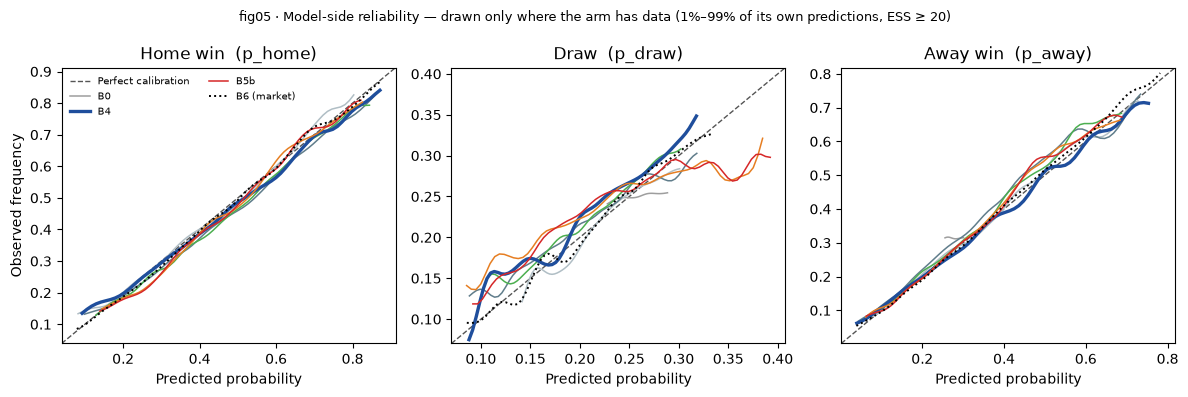

In [4]:
ARM_COLOR = {"B0": "#9e9e9e", "B1": "#b0bec5", "B2": "#607d8b", "B3": "#4caf50",
             "B4": "#1f4e9c", "B5a": "#e67e22", "B5b": "#d62728", "B6": "#000000"}
CLS_LABEL = {"home": "Home win", "draw": "Draw", "away": "Away win"}
MODEL_ARMS = ["B0", "B1", "B2", "B3", "B4", "B5a", "B5b"]

# 每面板横纵轴都取「各臂支撑的并集」，不再画到 0–1。旧版画满 0–1 的后果：平局面板
# 有 60% 的横轴没有任何一场比赛，曲线在那里是纯外推。
fig, axes = plt.subplots(1, 3, figsize=(12, 4.0))
for ax, (cls, cid, col) in zip(axes, CLS):
    d_all = rel_df[rel_df.cls == cls]
    lo, hi = float(d_all["x"].min()), float(d_all["x"].max())
    pad = 0.05 * (hi - lo)
    lim = (max(0.0, lo - pad), min(1.0, hi + pad))
    ax.plot(lim, lim, color="#555", lw=1, ls="--", label="Perfect calibration")
    for arm in MODEL_ARMS:
        d = d_all[d_all.arm == arm].sort_values("x")
        ax.plot(d["x"], d["y"], color=ARM_COLOR[arm], lw=(2.4 if arm == "B4" else 1.1),
                label=(arm if arm in ("B4", "B0", "B5b") else "_nolegend_"))
    db6 = d_all[d_all.arm == "B6"].sort_values("x")
    ax.plot(db6["x"], db6["y"], color="black", lw=1.4, ls=":", label="B6 (market)")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{CLS_LABEL[cls]}  ({col})")
    ax.set_xlabel("Predicted probability")
    if cls == "home":
        ax.set_ylabel("Observed frequency")
axes[0].legend(loc="upper left", frameon=False, ncol=2, fontsize=7)
fig.suptitle("fig05 · Model-side reliability — drawn only where the arm has data "
             "(1%–99% of its own predictions, ESS ≥ 20)", fontsize=9.5)
fig.tight_layout()
fig.savefig(FIG / "fig05_model_reliability.png", dpi=300, bbox_inches="tight")
plt.show()


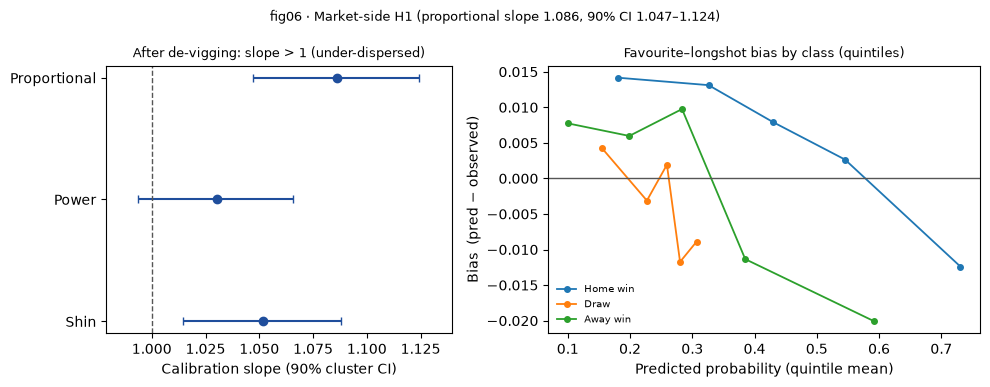

In [5]:
# fig06：市场侧。左＝三法去抽水的校准斜率（数字从 m2_verdicts.csv 读出，不硬编码）；
# 右＝按十分位箱的「偏差 vs 预测概率」（数据来自 m5_tail_bias.csv，与 tail_bin_bias 同口径）。
# 旧版右图是「三类 × 两尾」柱状图、图例写 <8%/>85%，而代码用的是十分位箱——标签与口径不符，
# 且六个数字是手抄字面量。现改为直接画偏差曲线，尾箱数由 CSV 提供。
import re

verdicts = pd.read_csv(OUT / "m2_verdicts.csv")
row = verdicts[verdicts.hypothesis.str.startswith("H1 斜率")].iloc[0]
m_shin = re.search(r"Shin\s+([\d.]+)\s+\[([\d.]+),([\d.]+)\]", row.detail)
m_pow = re.search(r"power\s+([\d.]+)\s+\[([\d.]+),([\d.]+)\]", row.detail)
assert m_shin and m_pow, row.detail
labels = ["Proportional", "Power", "Shin"]
slope = [float(row.point), float(m_pow.group(1)), float(m_shin.group(1))]
lo = [float(row.lo), float(m_pow.group(2)), float(m_shin.group(2))]
hi = [float(row.hi), float(m_pow.group(3)), float(m_shin.group(3))]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
yy = np.arange(3)[::-1]
for yi, s, l, h in zip(yy, slope, lo, hi):
    ax.errorbar(s, yi, xerr=[[s - l], [h - s]], fmt="o", color="#1f4e9c", capsize=3)
ax.axvline(1.0, color="#555", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(labels)
ax.set_xlabel("Calibration slope (90% cluster CI)")
ax.set_title("After de-vigging: slope > 1 (under-dispersed)", fontsize=9)
ax.set_xlim(min(lo) - 0.015, max(hi) + 0.015)

ax = axes[1]
tb = pd.read_csv(OUT / "m5_tail_bias.csv")
tb = tb[tb.nbins == 5]      # 展示用五分位（每箱约 3,300 场，二项噪声 ±0.008）；十分位明细同表可查
for name, cid, col in CLS:
    d = tb[(tb.arm == "B6") & (tb.cls == name)].sort_values("bin")
    ax.plot(d["pred_mean"], d["bias"], "o-", ms=4, lw=1.3, label=CLS_LABEL[name])
ax.axhline(0, color="#555", lw=1)
ax.set_xlabel("Predicted probability (quintile mean)")
ax.set_ylabel("Bias  (pred − observed)")
ax.set_title("Favourite–longshot bias by class (quintiles)", fontsize=9)
ax.legend(frameon=False, fontsize=7, loc="lower left")
fig.tight_layout()
title = "fig06 · Market-side H1 (proportional slope %.3f, 90%% CI %.3f–%.3f)" % (slope[0], lo[0], hi[0])
fig.suptitle(title, fontsize=9.5)
fig.tight_layout()
fig.savefig(FIG / "fig06_market_calibration.png", dpi=300, bbox_inches="tight")
plt.show()


## 结论（供报告 §5.2 使用）

1. **市场 under-dispersed**：B6 三类斜率 1.061 / 1.092 / 1.076，全部 > 1；比例法 pooled 斜率 1.086（90% CI 1.047–1.124），低概率区被高估、高概率区被低估（FLB）——H1 主判据支持。
2. **模型 over-dispersed，但不是均匀的**：B4 三类 0.940 / 0.944 / 0.964；两个 GBM 臂平局塌到 0.528 / 0.566，胜负两类反而 1.08–1.11（不足离散）。容量在同时扭曲三类。
3. **更强的模型没修好平局**：B5a/B5b 是阶梯里平局校准最差的两臂（0.528 / 0.566），而它们在胜负两类上过校正到了相反方向。
4. **平局不是被高估，是被低估**：在 p_draw ∈ [0.20, 0.35] 这一段，B3 −0.014、B4 −0.020（低估 1.4–2.0 个百分点），B0/B1/B2 才是正的。卡片原预期的「高估」方向是错的。
5. **ECE 与斜率给相反信号**：改口径后三类 ECE 全升、三类斜率全向 1 靠近。**以斜率为唯一判定统计量**，ECE 只作描述。

这五条拼起来就是完整的 H1：**市场与模型各有方向相反、形状不同的校准缺陷**，且「换更强的模型」没有修好任何一类。
